In [17]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv("datos_regresion.csv")

In [4]:
df.head()

,x1,x2,x3,x4,y
0,12.4,45.2,3.1,102.5,142.8
1,15.1,38.9,4.5,115.0,158.4
2,10.8,52.1,2.8,98.2,139.1
3,18.3,31.4,5.2,130.4,171.2
4,14.0,41.0,4.0,110.8,151.6


In [5]:
X = df[['x1', 'x2', 'x3', 'x4']]
y = df['y']

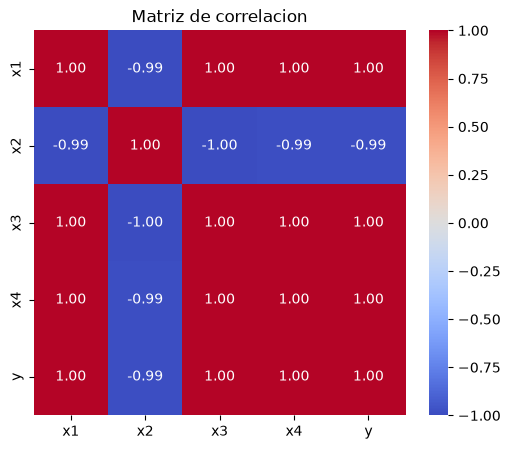

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

corr = df.corr()

plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Matriz de correlacion')
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.20, random_state=42
)

print(f"Dimensiones Train: {X_train.shape[0]} muestras")
print(f"Dimensiones Test: {X_test.shape[0]} muestras")


Dimensiones Train: 28 muestras
Dimensiones Test: 7 muestras


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

x_test_scaled = scaler.transform(X_test)

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [12]:
#Modelo A - sin escalar
model_raw = LinearRegression()
model_raw.fit(X_train, y_train)

#Modelo B - escalado
model_scaled = LinearRegression()
model_scaled.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 0.58,-0.43, 4.65,16.12]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,154.7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,4
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[10.56, 0.59, 0.32, 0.15]"


In [13]:
coef_comparison  =pd.DataFrame({
    'Variable': ['x1', 'x2', 'x3', 'x4'],
    'Beta (sin escalar)': model_raw.coef_,
    'Beta Estandarizado': model_raw.coef_
})

print(coef_comparison)


  Variable  Beta (sin escalar)  Beta Estandarizado
0       x1            0.135746            0.135746
1       x2           -0.035942           -0.035942
2       x3            3.159873            3.159873
3       x4            0.824779            0.824779


In [18]:
#Evaluacion
y_pred_raw = model_raw.predict(X_test)
y_pred_scaled = model_scaled.predict(x_test_scaled)

y_pred_train = model_scaled.predict(X_train_scaled)

print("--- Evaluación en Test (Sin Escalar vs Escalado) ---")
print(f"R² sin escalar:   {r2_score(y_test, y_pred_raw):.5f}")
print(f"R² estandarizado: {r2_score(y_test, y_pred_scaled):.5f}")
print(f"RMSE test:        {np.sqrt(mean_squared_error(y_test, y_pred_scaled)):.4f}")

print("\n--- Diagnóstico Train vs Test ---")
print(f"R² Train: {r2_score(y_train, y_pred_train):.5f}")
print(f"R² Test:  {r2_score(y_test, y_pred_scaled):.5f}")


--- Evaluación en Test (Sin Escalar vs Escalado) ---
R² sin escalar:   0.99840
R² estandarizado: 0.99840
RMSE test:        0.8468

--- Diagnóstico Train vs Test ---
R² Train: 0.99870
R² Test:  0.99840


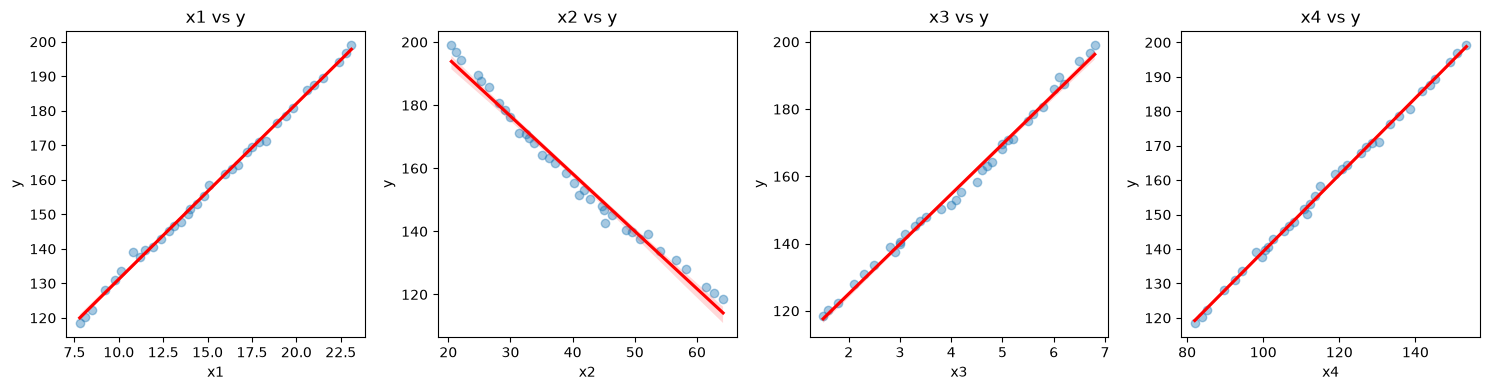

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
variables = ['x1', 'x2', 'x3', 'x4']

for ax, var in zip(axes, variables):
    sns.regplot(data=df, x=var, y='y', ax=ax,
                scatter_kws={'alpha': 0.4}, line_kws={'color': 'red'})
    ax.set_title(f'{var} vs y')

plt.tight_layout()
plt.show()